# Figure 8A: insertion-session prediction trajectory

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from manuscript_analysis.contract import FEATURE_SETS
from manuscript_analysis.data import apply_scaler, make_blocks
from manuscript_analysis.figures.export import save_label_variants
from manuscript_analysis.figures.fig_utils import (
    APP_COLOUR, HISTORICAL_THRESHOLD, RECORDING_SCORE_EXPORTS, ROOT, get_out_path, report_saved,
)
from manuscript_analysis.figures.style import apply_paper_style
from manuscript_analysis.modeling import get_models

apply_paper_style()

OUTPUT_DIR = get_out_path('8A')
FIGURE_STEM = '8A_insertion_trajectory'
CSV_PATH = OUTPUT_DIR / f'{FIGURE_STEM}.csv'
SESSION = 'EXP20_AD-CO-DAY150-IN6_NOV24.dat'
CONDITION = 'AD-CO-DAY150'
NOISE_CUTOFF_SAMPLE = 3_919_190
SAMPLE_RATE_HZ = 20_000
BLOCK_SIZE = 500

models = get_models(ROOT / 'results' / 'matched_three_pipeline_run' / 'runs' / 'unsorted')
cached = pd.read_csv(RECORDING_SCORE_EXPORTS / 'insertion_model_recording_scores.csv').query('session == @SESSION')
assert len(cached) == 25 and set(cached['model_id']) == set(models) and cached['class_name'].eq(CONDITION).all()

In [2]:
recording = (
    pd.read_pickle(ROOT / 'input' / 'insertion' / 'insertion_dfs_Nov24.pkl')[CONDITION]
    .query('session == @SESSION and Sample > @NOISE_CUTOFF_SAMPLE')
    .reset_index(drop=True)
)
blocks = make_blocks(recording, features=FEATURE_SETS['all'], block_size=BLOCK_SIZE)
assert len(blocks) == 7, f'Expected seven post-cutoff blocks, found {len(blocks)}'

ensemble_block_prediction = np.vstack([
    model.predict(
        apply_scaler(blocks, scaler['lo'], scaler['hi'], scaler['mu'], scaler['sd']), batch_size=128, verbose=0
    ).reshape(-1)
    for model, scaler, _ in models.values()
]).mean(axis=0)
cumulative_prediction = np.cumsum(ensemble_block_prediction) / np.arange(1, len(blocks) + 1)

timestamps_s = recording['Sample'].iloc[BLOCK_SIZE - 1::BLOCK_SIZE].iloc[:len(blocks)].to_numpy() / SAMPLE_RATE_HZ
plot_data = pd.DataFrame({
    'block': np.arange(1, len(blocks) + 1),
    'time_s': timestamps_s,
    'ensemble_block_prediction': ensemble_block_prediction,
    'cumulative_prediction': cumulative_prediction,
    'session': SESSION,
    'condition': CONDITION,
})
plot_data.to_csv(CSV_PATH, index=False)
plot_data

,block,time_s,ensemble_block_prediction,cumulative_prediction,session,condition
0,1,275.14460,0.243110,0.243110,EXP20_AD-CO-DAY150-IN6_NOV24.dat,AD-CO-DAY150
1,2,288.97380,0.908226,0.575668,EXP20_AD-CO-DAY150-IN6_NOV24.dat,AD-CO-DAY150
2,3,294.79085,0.818933,0.656756,EXP20_AD-CO-DAY150-IN6_NOV24.dat,AD-CO-DAY150
3,4,299.07145,0.857474,0.706936,EXP20_AD-CO-DAY150-IN6_NOV24.dat,AD-CO-DAY150
4,5,303.42860,0.865771,0.738703,EXP20_AD-CO-DAY150-IN6_NOV24.dat,AD-CO-DAY150
5,6,308.58085,0.922150,0.769277,EXP20_AD-CO-DAY150-IN6_NOV24.dat,AD-CO-DAY150
6,7,311.79375,0.893311,0.786996,EXP20_AD-CO-DAY150-IN6_NOV24.dat,AD-CO-DAY150


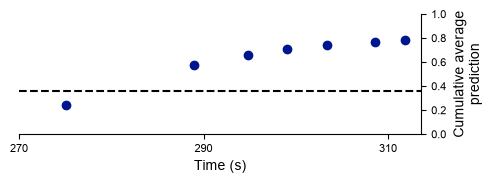

Saved output\figures\8A\8A_insertion_trajectory_with_labels.png
Saved output\figures\8A\8A_insertion_trajectory_with_labels.svg
Saved output\figures\8A\8A_insertion_trajectory_with_labels.pdf
Saved output\figures\8A\8A_insertion_trajectory_without_labels.png
Saved output\figures\8A\8A_insertion_trajectory_without_labels.svg
Saved output\figures\8A\8A_insertion_trajectory_without_labels.pdf
Saved output\figures\8A\8A_insertion_trajectory.csv


In [3]:
fig, ax = plt.subplots(figsize=(5, 1.9))
ax.plot(timestamps_s, cumulative_prediction, marker='o', linestyle='None', color=APP_COLOUR)
ax.axhline(HISTORICAL_THRESHOLD, color='black', linestyle='--', linewidth=1.5)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Cumulative average\nprediction', fontsize=10)
ax.set_ylim(0, 1)
ax.set_xticks(np.arange(270, 320, 20))
ax.yaxis.tick_right()
ax.yaxis.set_label_position('right')
ax.spines[['top', 'left']].set_visible(False)
fig.tight_layout()

saved_paths = save_label_variants(fig, OUTPUT_DIR, FIGURE_STEM)
plt.show()
report_saved([*saved_paths, CSV_PATH])